In [223]:
import pulp as plp
import matplotlib.pyplot as plt
from itertools import product

In [224]:
comprimentos_palete = [8, 50, 50]
larguras_palete = [6, 50, 40]

comprimentos_caixa = [3, 5, 7]
larguras_caixa = [2, 4, 6]

In [225]:
indice = 0
palete_comprimento = comprimentos_palete[indice]
palete_largura = larguras_palete[indice]

caixa_comprimento = comprimentos_caixa[indice]
caixa_largura = larguras_caixa[indice]

print(f"Dimensões do palete: {palete_comprimento}x{palete_largura}")
print(f"Dimensões da caixa: {caixa_comprimento}x{caixa_largura}")

Dimensões do palete: 8x6
Dimensões da caixa: 3x2


In [226]:
dimensoes_palete = [palete_comprimento, palete_largura] #lista
L,W = sorted(dimensoes_palete, reverse=True)
print(f"Dimensões classificadas do palete: {L}x{W}")

Dimensões classificadas do palete: 8x6


In [227]:
dimensoes_caixa = [caixa_comprimento, caixa_largura] #lista
l_um,w_um = sorted(dimensoes_caixa, reverse=True) # caixa deitada
print(f"Dimensões classificadas do caixa deitada: {l_um}x{w_um}")

Dimensões classificadas do caixa deitada: 3x2


In [228]:
l_dois, w_dois = dimensoes_caixa[::-1]
print(f"Dimensões classificadas do caixa em pé: {l_dois}x{w_dois}")

Dimensões classificadas do caixa em pé: 2x3


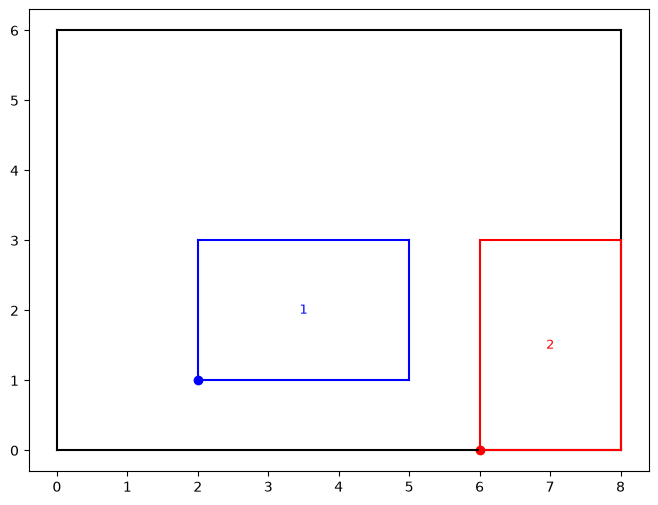

In [229]:
def plotar_caixa(bottom_left: list,
                l: int,
                w: int,
                color: str,
                label: str):
    x0, y0 = bottom_left
    plt.scatter(x=x0 ,y=y0, color=color)
    plt.plot([x0, x0+l], [y0, y0], color=color)
    plt.plot([x0, x0], [y0, y0+w], color=color)
    plt.plot([x0, x0 + l], [y0 + w, y0 + w], color=color)
    plt.plot([x0 + l, x0 + l], [y0, y0 + w], color=color)
    plt.text(x=x0+l/2, y=y0 + w/2, s=label, color=color,
             fontsize=9, ha="center", va="center")

def plotar_palete(L:int, W:int):
    plt.figure(figsize=(8,6))
    plt.plot([0,L], [0,0],"k")
    plt.plot([0,0], [0,W],"k")
    plt.plot([0,L], [W,W],"k")
    plt.plot([L,L], [0,W],"k")
    
plotar_palete(L,W)
plotar_caixa(bottom_left=[2,1], l=3, w=2, color="blue", label="1")
plotar_caixa(bottom_left=[6,0], l=2, w=3, color="red", label="2")

In [230]:
f_um = lambda n_um, l_um, n_dois, l_dois:\
    n_um * l_um + n_dois * l_dois

f_dois = lambda n_um, w_um, n_dois, w_dois:\
    n_um * w_um + n_dois * w_dois


In [231]:
print(f_um(n_um=1, l_um=3, n_dois=2, l_dois=2))

7


In [232]:
print(f_um(n_um=0, l_um=3, n_dois=3, l_dois=2))

6


In [233]:
print(f_um(n_um=2, l_um=3, n_dois=1, l_dois=2))

8


In [234]:
print(f_um(n_um=1, l_um=3, n_dois=2, l_dois=2)) # uma caixa em pé p=7  # p <= L - w_um

7


In [235]:
print(f_dois(n_um=2, w_um=2, n_dois=0, w_dois=3)) # q=4 # q <= W = w_um

4


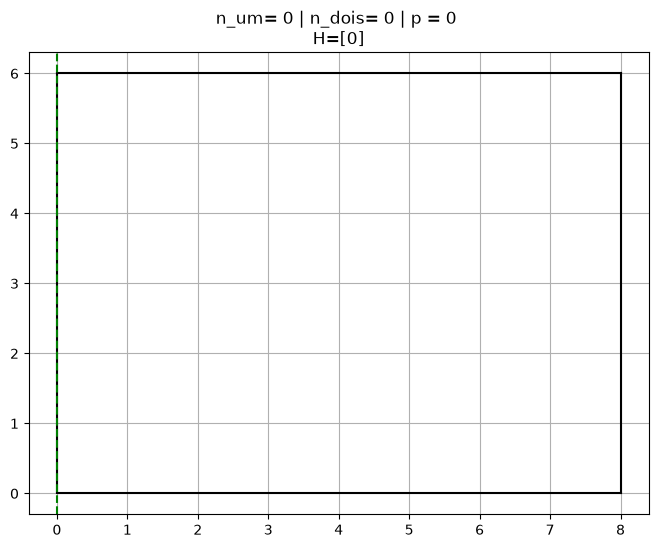

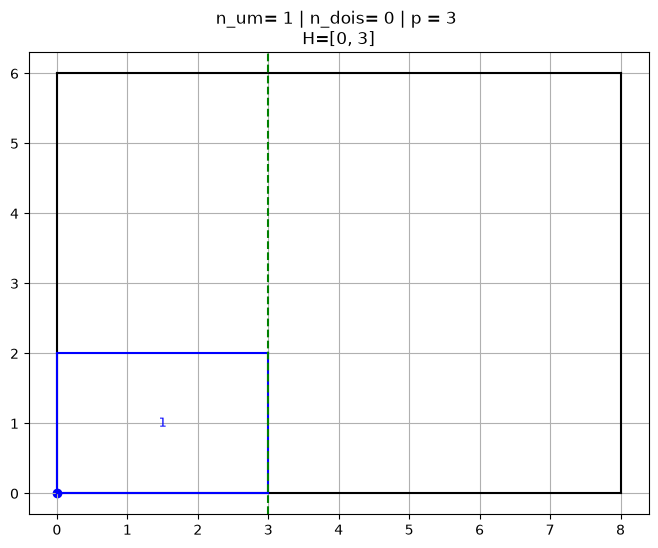

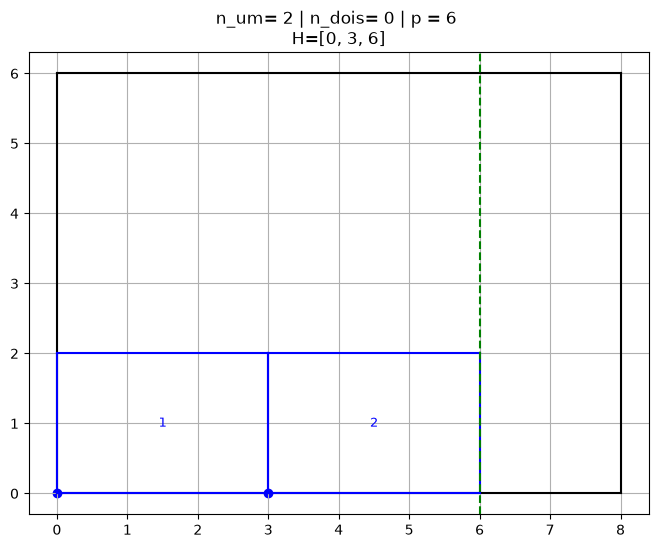

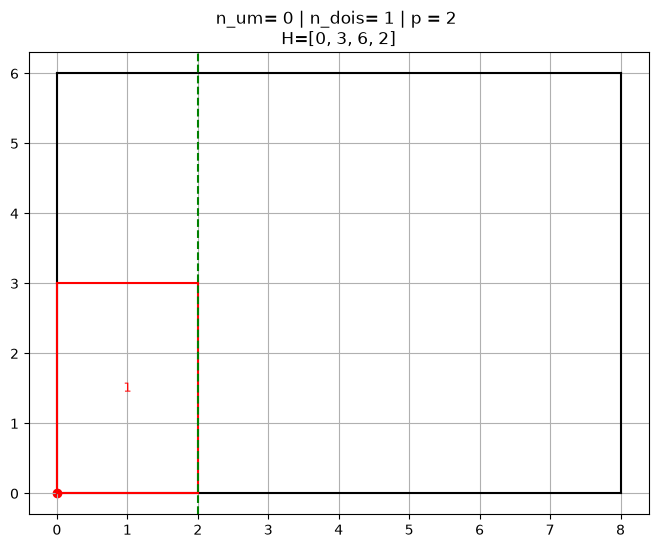

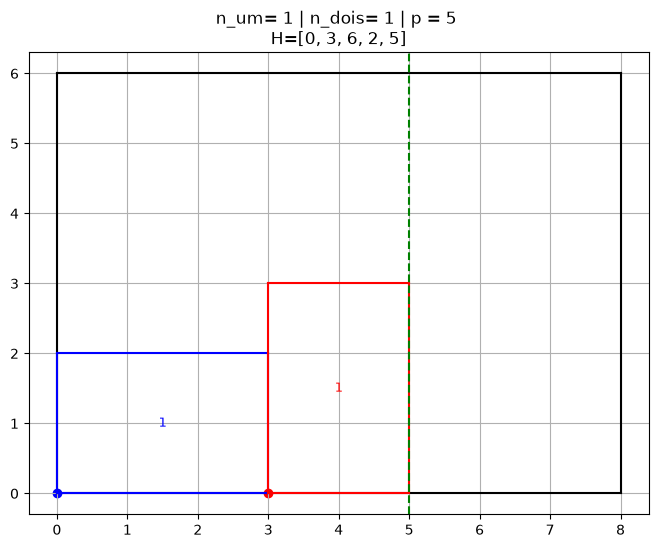

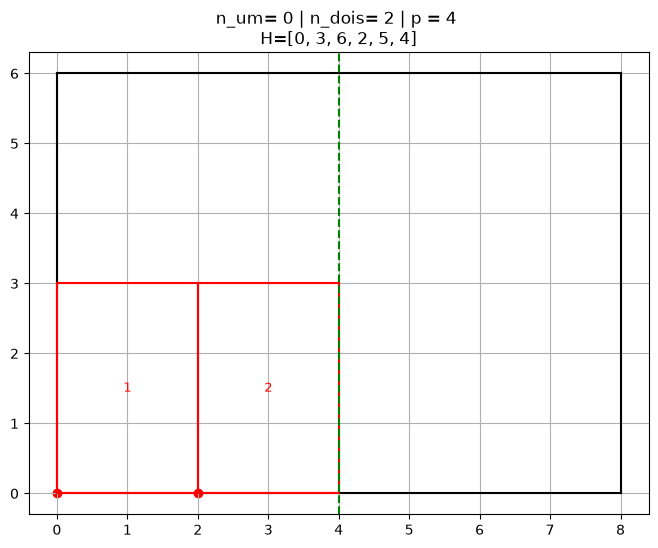

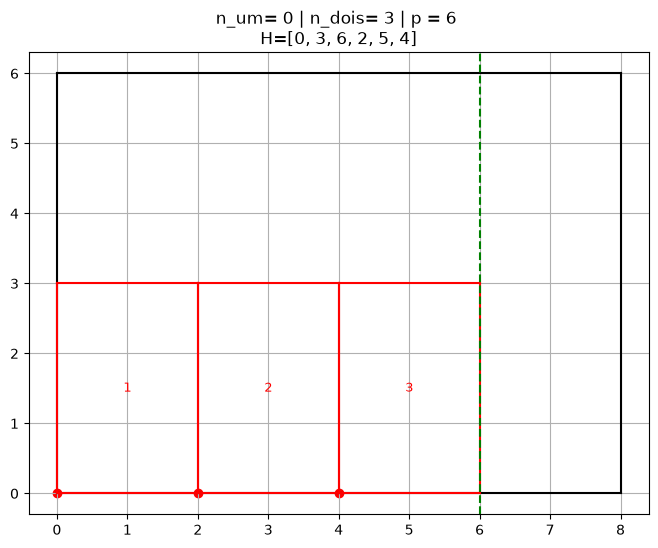

In [236]:
# teste de encaixe de p e q
H = []
for n_dois, n_um in product(range(L), range(L)): # product um com todos, todos com um
    #print(n_um, n_dois)
    p = f_um(n_um, l_um, n_dois, l_dois)
    #print(n_um, n_dois, p) # deixar o for sem repetir
    if p <= L - w_um:

        if p not in H:
            H.append(p)

        plotar_palete(L,W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[n*l_um, 0], l=l_um, w=w_um,
            color = "blue", label = n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[n_um * l_um + n * l_dois, 0],
                         l=l_dois, w=w_dois, color="red",
                         label =n+1)

        plt.axvline(x=p, color="green", linestyle="--")
        plt.title(f"{n_um= } | {n_dois= } | {p = } \n{H=}")
        plt.grid()

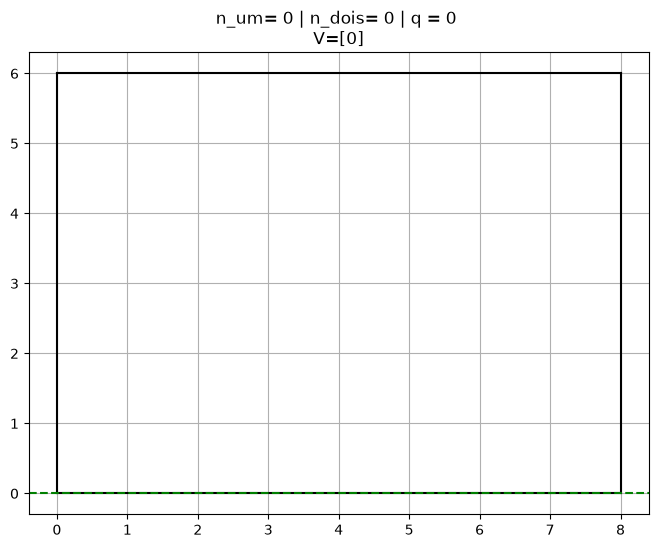

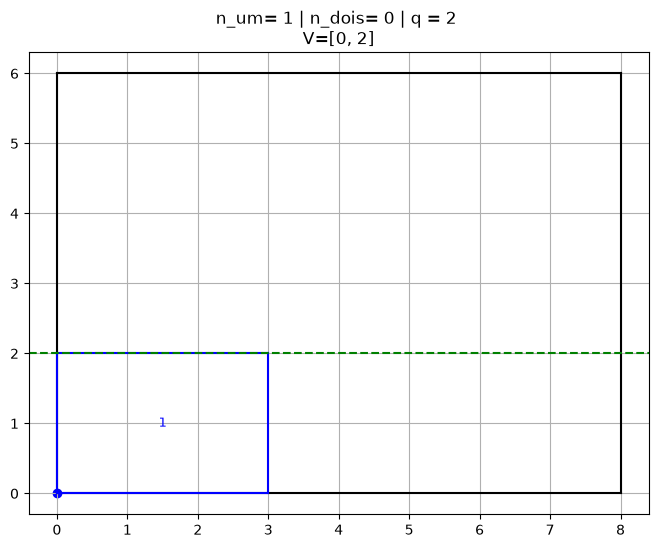

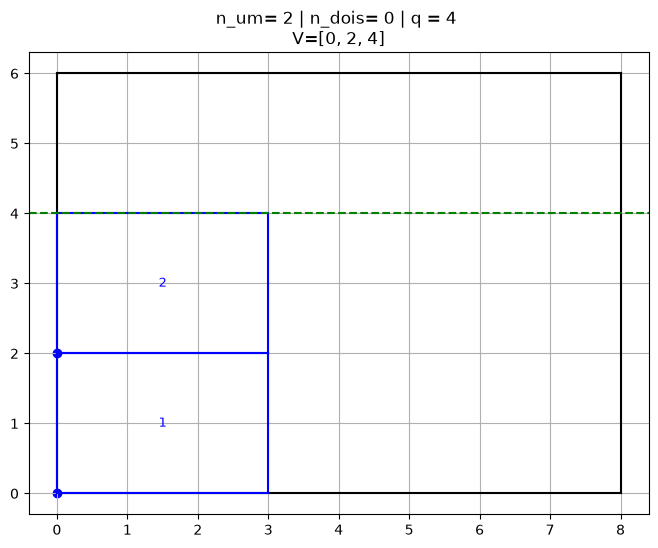

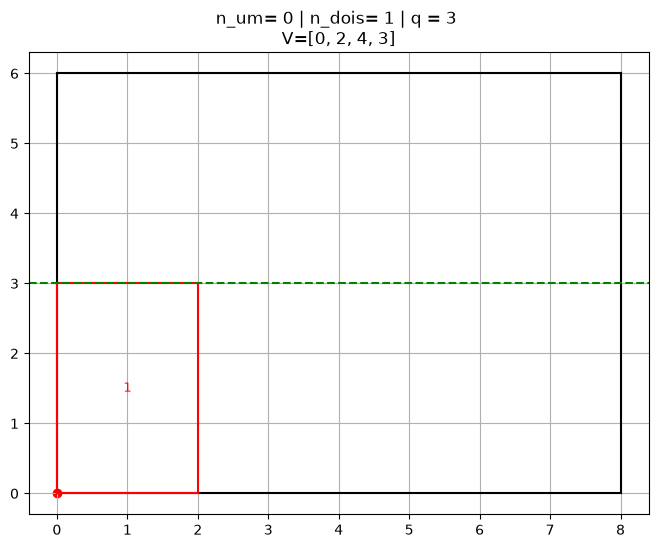

In [237]:
V = []
for n_dois, n_um in product(range(L), range(L)): # product um com todos, todos com um
    #print(n_um, n_dois)
    q = f_dois(n_um, w_um, n_dois, w_dois)
    #print(n_um, n_dois, q) # deixar o for sem repetir
    if q <= W - w_um:

        if q not in V:
            V.append(q)

        plotar_palete(L,W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[0, n*w_um], l=l_um, w=w_um,
            color = "blue", label = n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[0, n_um * w_um + n * w_dois],
                         l=l_dois, w=w_dois, color="red",
                         label =n+1)

        plt.axhline(y=q, color="green", linestyle="--")
        plt.title(f"{n_um= } | {n_dois= } | {q = } \n{V=}")
        plt.grid()

In [238]:
H = sorted(H)
V = sorted(V)

print(H)
print(V)

[0, 2, 3, 4, 5, 6]
[0, 2, 3, 4]


In [239]:
lista_rs = list(product(H,V)) # rs, combinatários entre todos os H x V (Horizontal x Vertical) o 6,4 não é validado tem que ser eliminado
display(lista_rs)

[(0, 0),
 (0, 2),
 (0, 3),
 (0, 4),
 (2, 0),
 (2, 2),
 (2, 3),
 (2, 4),
 (3, 0),
 (3, 2),
 (3, 3),
 (3, 4),
 (4, 0),
 (4, 2),
 (4, 3),
 (4, 4),
 (5, 0),
 (5, 2),
 (5, 3),
 (5, 4),
 (6, 0),
 (6, 2),
 (6, 3),
 (6, 4)]

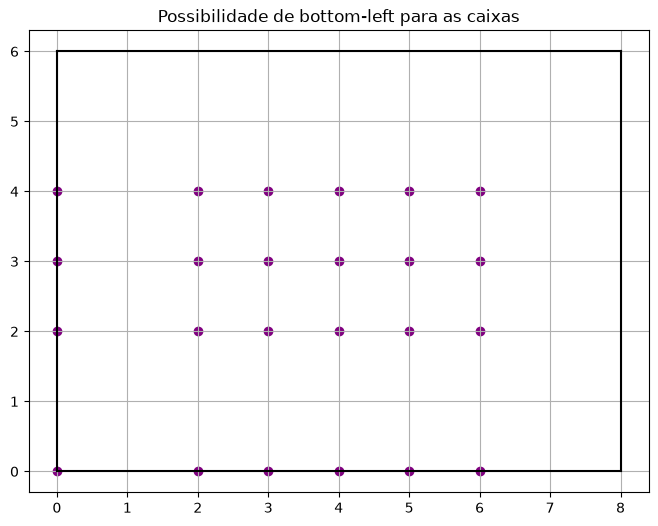

In [240]:
# pontos possiveis
if indice ==0:
    plotar_palete(L,W)
    for r,s in lista_rs:
        plt.scatter(x=r, y=s, color = "purple")

    plt.title("Possibilidade de bottom-left para as caixas")
    plt.grid()
    plt.show()

In [241]:
# ls lista dos dois s
# ws lists dos dois w

ls= [l_um, l_dois]
ws= [w_um, w_dois]

In [242]:
#i =1
#print(ls[i], ws[i]) # aqui comeca em 2

In [243]:
i =1
print(ls[i-1], ws[i-1]) # agora começa em 0

3 2


In [244]:
# # Lista de tupla para montar a Função Objetiva
# plotar_palete(L,W)
# for i, (p, q) in product([1,2], lista_rs):
#     print(i,p,q)

In [245]:
# # Lista de tupla para montar a Função Objetiva 
# lista_variaveis = []
# plotar_palete(L, W)
# for (p, q), i in product(lista_rs, [1,2]):
#     #print(i,p,q)
#     # i = 1 (caixa deitada)
#     # i = 2 (caixa em pé)
#     if p +ls[i-1] <= L and q + ws[i-1] <=W: # checa se cabe no palete, se futuro é O ou 1 (cabe ou não cabe)
#         lista_variaveis.append((i,p,q)) # tulpa i,p,q

#     if indice == 0:
#         cor = "blue" if i==1 else "red"
#         plt.scatter(x=p, y=q, color=cor) # plotar o bottom-leff

#         if i==1: #caixa deitada
#             plt.text(x=p - 0.3, y=q + 0.15, s=f"{i},{p},{q}",
#             color=cor, fontsize=10)

#         else: # caixa sendo 2 em pé
#             plt.text(x=p - 0.3, y=q - 0.25, s=f"{i},{p},{q}",
#             color=cor, fontsize=10)

# o codigo acima não está filtrado os pontos no codigo abaixo os if´s estão em cascata

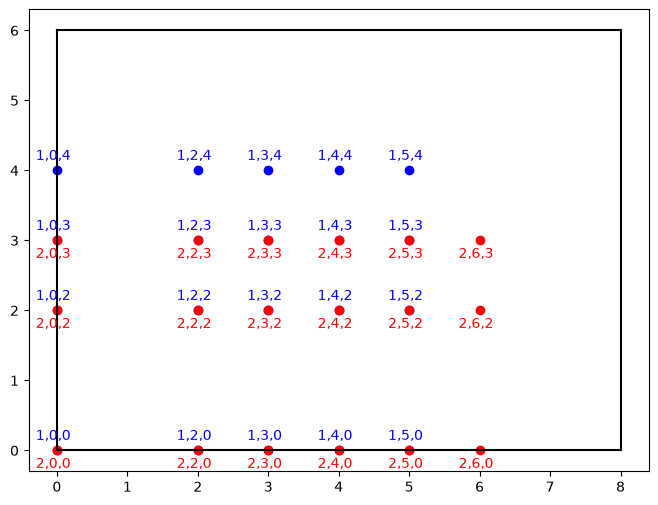

In [246]:
# Lista de tupla para montar a Função Objetiva
lista_variaveis = []
plotar_palete(L, W)
for (p, q), i in product(lista_rs, [1,2]): # poderia ser r e s
    #print(i,p,q)
    # i = 1 (caixa deitada)
    # i = 2 (caixa em pé)
    if p +ls[i-1] <= L and q + ws[i-1] <=W: # checa se cabe no palete, se futuro é O ou 1 (cabe ou não cabe)
        lista_variaveis.append((i,p,q)) # tulpa i,p,q

        if indice == 0:
            cor = "blue" if i==1 else "red"
            plt.scatter(x=p, y=q, color=cor) # plotar o bottom-leff

            if i==1: #caixa deitada
                plt.text(x=p - 0.3, y=q + 0.15, s=f"{i},{p},{q}",
                color=cor, fontsize=10)

            else: # caixa sendo 2 em pé
                plt.text(x=p - 0.3, y=q - 0.25, s=f"{i},{p},{q}",
                color=cor, fontsize=10)

In [247]:
print(len(lista_variaveis))

38


In [248]:
prob = plp.LpProblem(name="Palete_caixa",
                     sense=plp.LpMaximize)
display(prob)

Palete_caixa:
MAXIMIZE
None
VARIABLES

In [249]:
# transforma a lista de variaveis

dict_variaveis = plp.LpVariable.dicts(name="C", indices=lista_variaveis,
                                lowBound=0, upBound=1,
                                cat=plp.LpBinary) # transforma a tupla em O ou 1 o pulp fez isso

display(dict_variaveis) #dicionário (1,0,0) C_(1,0,0) valores

{(1, 0, 0): C_(1,_0,_0),
 (2, 0, 0): C_(2,_0,_0),
 (1, 0, 2): C_(1,_0,_2),
 (2, 0, 2): C_(2,_0,_2),
 (1, 0, 3): C_(1,_0,_3),
 (2, 0, 3): C_(2,_0,_3),
 (1, 0, 4): C_(1,_0,_4),
 (1, 2, 0): C_(1,_2,_0),
 (2, 2, 0): C_(2,_2,_0),
 (1, 2, 2): C_(1,_2,_2),
 (2, 2, 2): C_(2,_2,_2),
 (1, 2, 3): C_(1,_2,_3),
 (2, 2, 3): C_(2,_2,_3),
 (1, 2, 4): C_(1,_2,_4),
 (1, 3, 0): C_(1,_3,_0),
 (2, 3, 0): C_(2,_3,_0),
 (1, 3, 2): C_(1,_3,_2),
 (2, 3, 2): C_(2,_3,_2),
 (1, 3, 3): C_(1,_3,_3),
 (2, 3, 3): C_(2,_3,_3),
 (1, 3, 4): C_(1,_3,_4),
 (1, 4, 0): C_(1,_4,_0),
 (2, 4, 0): C_(2,_4,_0),
 (1, 4, 2): C_(1,_4,_2),
 (2, 4, 2): C_(2,_4,_2),
 (1, 4, 3): C_(1,_4,_3),
 (2, 4, 3): C_(2,_4,_3),
 (1, 4, 4): C_(1,_4,_4),
 (1, 5, 0): C_(1,_5,_0),
 (2, 5, 0): C_(2,_5,_0),
 (1, 5, 2): C_(1,_5,_2),
 (2, 5, 2): C_(2,_5,_2),
 (1, 5, 3): C_(1,_5,_3),
 (2, 5, 3): C_(2,_5,_3),
 (1, 5, 4): C_(1,_5,_4),
 (2, 6, 0): C_(2,_6,_0),
 (2, 6, 2): C_(2,_6,_2),
 (2, 6, 3): C_(2,_6,_3)}

In [250]:
#dict_variaveis.values()
#sum(dict_variaveis.values()) #sum somatória, C, colocar a caixa no lugar especifico
prob += sum(dict_variaveis.values())
display(prob)

Palete_caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0
VARIABLES
0 <= C_(1,_0,_0) <= 1 Integer
0 <= C_(1,_0,_2) <= 1 Integer
0 <= C_(1,_0,_3) <= 1 Integer
0 <= C_(1,_0,_4) <= 1 Integer
0 <= C_(1,_2,_0) <= 1 Integer
0 <= C_(1,_2,_2) <= 1 Integer
0 <= C_(1,_2,_3) <= 1 Integer
0 <= C_(1,_2,_4) <= 1 Integer
0 <= C_(1,_3,_0) <= 1 Integer
0 <= C_(1,_3,_2) <= 1 Integer
0 <= C_(1,_3,_3) <= 1 Integer
0 <= C_(1,_3,_4) <= 1 Integ

In [251]:
print(f"Qtd variaveis: {prob.numVariables()}")
print(f"Qtd restricaoes: {prob.numConstraints()}")

Qtd variaveis: 38
Qtd restricaoes: 0


In [252]:
def ponto_dentro_caixa(ponto_rs: tuple,
                        ponto_pq: tuple,
                        l: int, w: int) ->bool:
    r, s = ponto_rs
    p, q = ponto_pq
    return p <=r < p + l and q <= s < q + w

print(ponto_dentro_caixa((6,2),
                        (6,0),
                        l=ls[0],w=ws[0]))

False


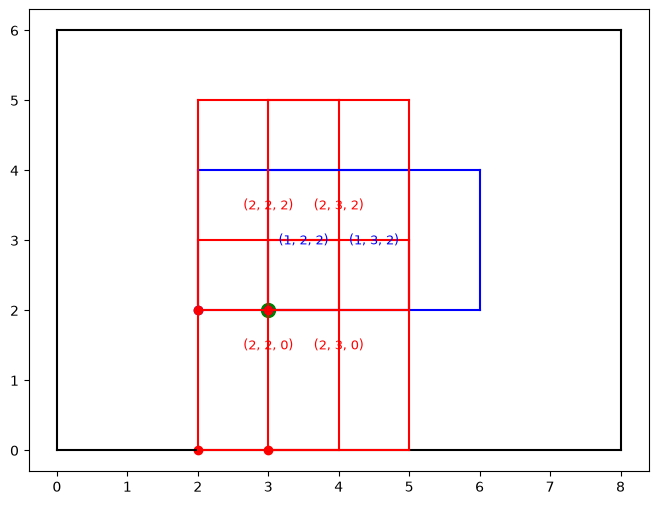

In [253]:
plotar_palete(L,W)
r,s = lista_rs[9]
plt.scatter(x=r, y=s, color="green", s=100)
caixas_sobrepostas = []
for i,p,q in lista_variaveis:
    if ponto_dentro_caixa((r,s),
                        (p,q),
                        l=ls[i-1], w=ws[i-1]):
        plotar_caixa((p,q), ls[i-1], ws[i-1],
                    color="blue" if i==1 else "red",
                    label=f"{i,p, q}") #numero

In [254]:
#sorted((2,0,2), (1,1,2)) # lista de tupla

In [255]:
#plotar_palete(L,W)
n=0
for r, s in lista_rs:
    caixas_sobrepostas = []
    for i,p , q in lista_variaveis:
        if ponto_dentro_caixa((r,s),
                            (p,q),
                            l=ls[i-1], w=ws[i-1]):
            caixas_sobrepostas.append(dict_variaveis[i, p, q]) #slide de dicionario cada tupla em C
    #print(sorted(caixas_sobrepostas))
    #print(sum((caixas_sobrepostas)))
    prob+=sum(caixas_sobrepostas) <=1, f"Restricao 1.{n}"
    n+=1

In [256]:
qtd_maxima_caixa = (L*W)//(l_um *w_um)
#display(prob)
print(qtd_maxima_caixa)

8


In [257]:
print(prob.numVariables())
print(prob.numConstraints())

38
24


In [258]:
prob+= sum(dict_variaveis.values()) <= qtd_maxima_caixa, "Restricao_2.0"
display(prob)

Palete_caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0
SUBJECT TO
Restricao_1.0: C_(1,_0,_0) + C_(2,_0,_0) <= 1

Restricao_1.1: C_(1,_0,_2) + C_(2,_0,_0) + C_(2,_0,_2) <= 1

Restricao_1.2: C_(1,_0,_2) + C_(1,_0,_3) + C_(2,_0,_2) + C_(2,_0,_3) <= 1

Restricao_1.3: C_(1,_0,_3) + C_(1,_0,_4) + C_(2,_0,_2) + C_(2,_0,_3) <= 1

Restricao_1.4: C_(1,_0,_0) + C_(1,_2,_0) + C_(2,_2,_0) <= 1

Restricao_1.5: C_(1,_0,_2) + C_(1,_2,

In [259]:
print(prob.numVariables())
print(prob.numConstraints())

38
25


In [261]:
solver = plp.getSolver("PULP_CBC_CMD", timeLimit=None)

In [262]:
prob.solve(solver)

1

In [263]:
display(plp.LpStatus)

{0: 'Not Solved',
 1: 'Optimal',
 -1: 'Infeasible',
 -2: 'Unbounded',
 -3: 'Undefined'}

In [266]:
print(prob.variables())

[C_(1,_0,_0), C_(1,_0,_2), C_(1,_0,_3), C_(1,_0,_4), C_(1,_2,_0), C_(1,_2,_2), C_(1,_2,_3), C_(1,_2,_4), C_(1,_3,_0), C_(1,_3,_2), C_(1,_3,_3), C_(1,_3,_4), C_(1,_4,_0), C_(1,_4,_2), C_(1,_4,_3), C_(1,_4,_4), C_(1,_5,_0), C_(1,_5,_2), C_(1,_5,_3), C_(1,_5,_4), C_(2,_0,_0), C_(2,_0,_2), C_(2,_0,_3), C_(2,_2,_0), C_(2,_2,_2), C_(2,_2,_3), C_(2,_3,_0), C_(2,_3,_2), C_(2,_3,_3), C_(2,_4,_0), C_(2,_4,_2), C_(2,_4,_3), C_(2,_5,_0), C_(2,_5,_2), C_(2,_5,_3), C_(2,_6,_0), C_(2,_6,_2), C_(2,_6,_3)]


In [ ]:
print(prob.variables()[0].name, prob.variables()[0].varValue)
print(prob.variables()[2].name, prob.variables()[2].varValue)
print(prob.objective.value())


C_(1,_0,_0) 1.0
C_(1,_0,_3) 0.0
8.0


In [277]:
dict_traducao = \
    dict(zip(dict_variaveis.values(),
        dict_variaveis.keys()))
display(dict_traducao)

{C_(1,_0,_0): (1, 0, 0),
 C_(2,_0,_0): (2, 0, 0),
 C_(1,_0,_2): (1, 0, 2),
 C_(2,_0,_2): (2, 0, 2),
 C_(1,_0,_3): (1, 0, 3),
 C_(2,_0,_3): (2, 0, 3),
 C_(1,_0,_4): (1, 0, 4),
 C_(1,_2,_0): (1, 2, 0),
 C_(2,_2,_0): (2, 2, 0),
 C_(1,_2,_2): (1, 2, 2),
 C_(2,_2,_2): (2, 2, 2),
 C_(1,_2,_3): (1, 2, 3),
 C_(2,_2,_3): (2, 2, 3),
 C_(1,_2,_4): (1, 2, 4),
 C_(1,_3,_0): (1, 3, 0),
 C_(2,_3,_0): (2, 3, 0),
 C_(1,_3,_2): (1, 3, 2),
 C_(2,_3,_2): (2, 3, 2),
 C_(1,_3,_3): (1, 3, 3),
 C_(2,_3,_3): (2, 3, 3),
 C_(1,_3,_4): (1, 3, 4),
 C_(1,_4,_0): (1, 4, 0),
 C_(2,_4,_0): (2, 4, 0),
 C_(1,_4,_2): (1, 4, 2),
 C_(2,_4,_2): (2, 4, 2),
 C_(1,_4,_3): (1, 4, 3),
 C_(2,_4,_3): (2, 4, 3),
 C_(1,_4,_4): (1, 4, 4),
 C_(1,_5,_0): (1, 5, 0),
 C_(2,_5,_0): (2, 5, 0),
 C_(1,_5,_2): (1, 5, 2),
 C_(2,_5,_2): (2, 5, 2),
 C_(1,_5,_3): (1, 5, 3),
 C_(2,_5,_3): (2, 5, 3),
 C_(1,_5,_4): (1, 5, 4),
 C_(2,_6,_0): (2, 6, 0),
 C_(2,_6,_2): (2, 6, 2),
 C_(2,_6,_3): (2, 6, 3)}

In [278]:
dict_variaveis

{(1, 0, 0): C_(1,_0,_0),
 (2, 0, 0): C_(2,_0,_0),
 (1, 0, 2): C_(1,_0,_2),
 (2, 0, 2): C_(2,_0,_2),
 (1, 0, 3): C_(1,_0,_3),
 (2, 0, 3): C_(2,_0,_3),
 (1, 0, 4): C_(1,_0,_4),
 (1, 2, 0): C_(1,_2,_0),
 (2, 2, 0): C_(2,_2,_0),
 (1, 2, 2): C_(1,_2,_2),
 (2, 2, 2): C_(2,_2,_2),
 (1, 2, 3): C_(1,_2,_3),
 (2, 2, 3): C_(2,_2,_3),
 (1, 2, 4): C_(1,_2,_4),
 (1, 3, 0): C_(1,_3,_0),
 (2, 3, 0): C_(2,_3,_0),
 (1, 3, 2): C_(1,_3,_2),
 (2, 3, 2): C_(2,_3,_2),
 (1, 3, 3): C_(1,_3,_3),
 (2, 3, 3): C_(2,_3,_3),
 (1, 3, 4): C_(1,_3,_4),
 (1, 4, 0): C_(1,_4,_0),
 (2, 4, 0): C_(2,_4,_0),
 (1, 4, 2): C_(1,_4,_2),
 (2, 4, 2): C_(2,_4,_2),
 (1, 4, 3): C_(1,_4,_3),
 (2, 4, 3): C_(2,_4,_3),
 (1, 4, 4): C_(1,_4,_4),
 (1, 5, 0): C_(1,_5,_0),
 (2, 5, 0): C_(2,_5,_0),
 (1, 5, 2): C_(1,_5,_2),
 (2, 5, 2): C_(2,_5,_2),
 (1, 5, 3): C_(1,_5,_3),
 (2, 5, 3): C_(2,_5,_3),
 (1, 5, 4): C_(1,_5,_4),
 (2, 6, 0): C_(2,_6,_0),
 (2, 6, 2): C_(2,_6,_2),
 (2, 6, 3): C_(2,_6,_3)}

In [283]:
variaveis_organizadas = []
for variavel in prob.variables():
   # print(variavel.name, variavel.varValue)
   if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)


[(1, 0, 0),
 (1, 0, 2),
 (1, 0, 4),
 (1, 3, 0),
 (1, 3, 2),
 (1, 3, 4),
 (2, 6, 0),
 (2, 6, 3)]

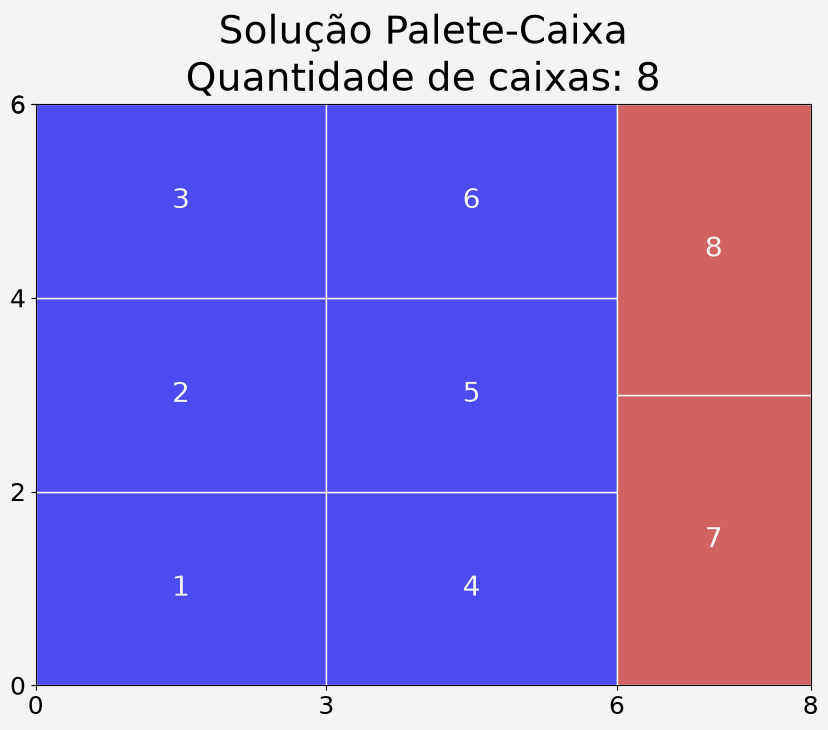

In [284]:
fig, ax = plt.subplots(figsize=(10, 10))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=20,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=28)

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=18)
ax.yaxis.set_tick_params(labelsize=18)

In [ ]:
from copy import deepcopy
solucoes = [deepcopy(variaveis_organizadas)] # senão colocar deepcopy ele poem o endereço da memoria e se houver mudança pode perdar o dado

In [288]:
#restricao 3
from random import random, seed
seed(42)

n = 0
for variavel in prob.variables(): # for percurre as 38 caixas
    if variavel.varValue >0:

        if random()> 0.2:
            continue #vai para proxima variavel

        #print(variavel)
        prob+= variavel ==0, f"Restricao_3.{n}"
        n+=1
display(prob)



Palete_caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0
SUBJECT TO
Restricao_1.0: C_(1,_0,_0) + C_(2,_0,_0) <= 1

Restricao_1.1: C_(1,_0,_2) + C_(2,_0,_0) + C_(2,_0,_2) <= 1

Restricao_1.2: C_(1,_0,_2) + C_(1,_0,_3) + C_(2,_0,_2) + C_(2,_0,_3) <= 1

Restricao_1.3: C_(1,_0,_3) + C_(1,_0,_4) + C_(2,_0,_2) + C_(2,_0,_3) <= 1

Restricao_1.4: C_(1,_0,_0) + C_(1,_2,_0) + C_(2,_2,_0) <= 1

Restricao_1.5: C_(1,_0,_2) + C_(1,_2,

In [291]:
print(prob.numVariables())
print(prob.numConstraints())

38
27


In [292]:
prob.solve(solver)

1

In [293]:
variaveis_organizadas = []
for variavel in prob.variables():
   # print(variavel.name, variavel.varValue)
   if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)

[(1, 2, 0),
 (1, 2, 2),
 (1, 2, 4),
 (1, 5, 0),
 (1, 5, 2),
 (1, 5, 4),
 (2, 0, 0),
 (2, 0, 3)]

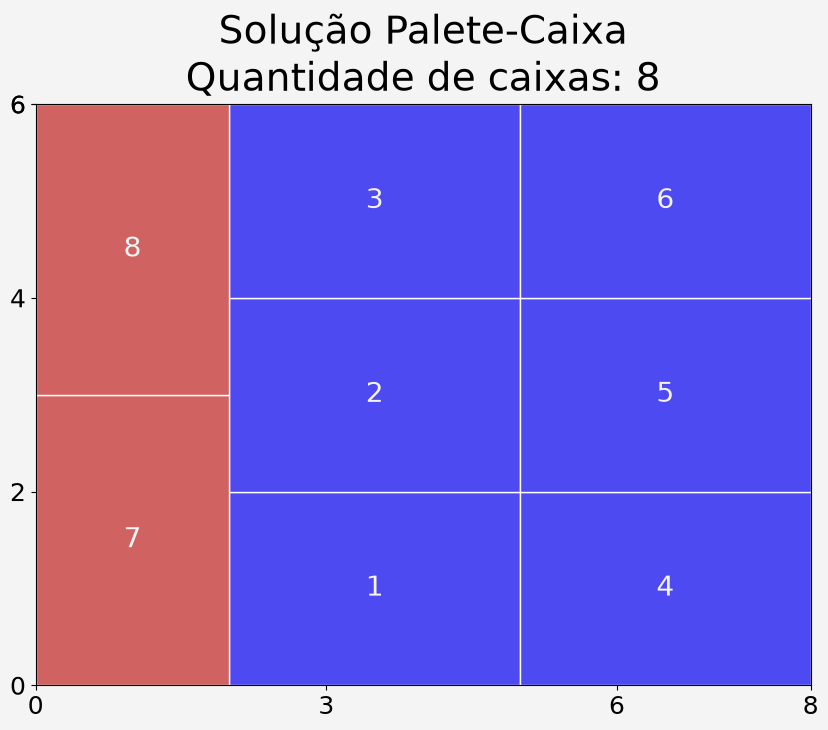

In [294]:
fig, ax = plt.subplots(figsize=(10, 10))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=20,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=28)

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=18)
ax.yaxis.set_tick_params(labelsize=18)